<a href="https://colab.research.google.com/github/timotheysski/Quantum-Time-of-Arrival-Papers/blob/main/DICE_FreeFall_Fig_vdef.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fig 1: TOA-position uncertainty and mean value of TOA for a free-falling particle


## Fig 1a: TOA-position uncertainty


<ipython-input-1-372c2e1aa624>:90: RuntimeWarning: divide by zero encountered in divide
  return hb0 / (2 * m0 * q * np.sqrt(2 * g0 * x0))  # Modify this function if you have the inverse transformation


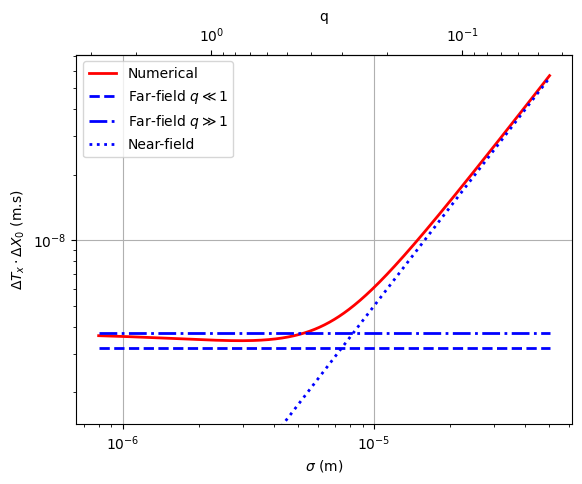

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma

k = np.sqrt(np.sqrt(2/np.pi) - (np.sqrt(2) * gamma(3/4)**2) / np.pi)

hb0 = 1.05e-34
m0 = 1.67e-27
g0 = 9.8
x0 = 1e-5
tc = np.sqrt(2*x0/g0)

def fc(y):
    return np.sqrt(1 + y**2) - y

def fb(y, b):
    return np.sqrt(1 + 2 * y**2 - y* np.sqrt(4 * y**2 + 4 + b**2 ))

def gq(y, q):
    return np.exp(-y**2 / (2 * q**2)) / np.sqrt(2 * np.pi * q**2)

def calculate_parameters(sigma, hb, m, g, x):
    q = hb / (2 * m * sigma * np.sqrt(2 * g * x))
    mu = sigma / x
    b = mu / q
    fc_val = fc(sigma)
    fb_val = fb(sigma, b)
    gq_val = gq(sigma, q)
    delta_tx = q

    return q, mu, b, fc_val, fb_val, gq_val, delta_tx

sigma_min = 8e-7
sigma_max = 5e-5
delta_sigma = 5e-8

hb = hb0
m = m0
g = g0
x = x0

TPro = []
TProAssySc = []
TProAssyQ = []
TProAssyShortFl = []
Tqvalue = []
Tsigma = []

for sigma in np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma):
    q_val, mu_val, b_val, fc_val, fb_val, gq_val, delta_tx_val = calculate_parameters(sigma, hb, m, g, x)

    integral_fb_sq_gq = quad(lambda y: fb(y, b_val)**2 * gq(y, q_val), -np.inf, 1/b_val)[0]
    integral_gq_q_mu_b = quad(lambda y: (gq(y, q_val)), -np.inf, 1/b_val)[0]
    integral_fb_gq_q_mu_b = quad(lambda y: fb(y, b_val) * gq(y, q_val) , -np.inf, 1/b_val)[0]

    if integral_gq_q_mu_b == 0:
        TPro.append(0)
    else:
        TPro.append(sigma * tc * np.sqrt((integral_fb_sq_gq / integral_gq_q_mu_b) - (integral_fb_gq_q_mu_b**2 / integral_gq_q_mu_b**2)))

    TProAssySc.append(sigma * tc * delta_tx_val)
    TProAssyQ.append(sigma * tc * q_val * np.sqrt(2 * (np.pi - 1) / np.pi))
    TProAssyShortFl.append(sigma * tc * k * np.sqrt(sigma / x0))

    Tqvalue.append(q_val)
    Tsigma.append(sigma)

# Plotting
fig, ax1 = plt.subplots()
#ax2 = ax1.twinx()

ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TPro, label='Numerical', color='red', linestyle='-', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TProAssySc, label='Far-field $q\ll 1$', color='blue', linestyle='--', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TProAssyQ, label='Far-field $q\gg 1$', color='blue', linestyle='-.', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TProAssyShortFl, label='Near-field', color='blue', linestyle=':', linewidth=2)

# Define the desired y-axis limits
y_min, y_max = 10**(-6) * tc, 0.5*10**(-4) * tc
# Set the y-axis limits
ax1.set_ylim(y_min, y_max)

ax1.set_xlabel(r'$\sigma$ (m)')
ax1.set_ylabel(r'$\Delta T_x \cdot \Delta X_0$ (m.s)')

def sigma_to_q(sigma):
    return hb0 / (2 * m0 * sigma * np.sqrt(2 * g0 * x0))

def q_to_sigma(q):
    return hb0 / (2 * m0 * q * np.sqrt(2 * g0 * x0))  # Modify this function if you have the inverse transformation

secax = ax1.secondary_xaxis('top', functions=(sigma_to_q, q_to_sigma))
secax.set_xlabel('q')

ax1.legend()
ax1.grid(True)
plt.show()



## Fig 1b: Mean TOA

<ipython-input-4-e9d3e7549e38>:22: RuntimeWarning: divide by zero encountered in divide
  return hb0 / (2 * m0 * q * np.sqrt(2 * g0 * x0))  # Modify this function if you have the inverse transformation


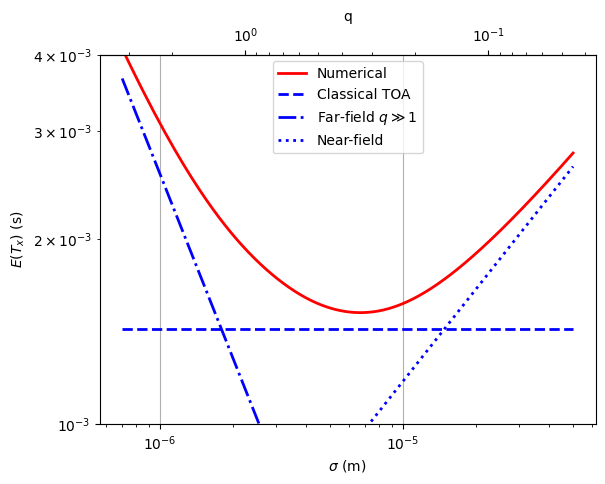

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma

k = 2**(1/4) * gamma(3/4) / np.sqrt(np.pi)

hb0 = 1.05e-34
m0 = 1.67e-27
g0 = 9.8
x0 = 1e-5
tc = np.sqrt(2*x0/g0)

def fc(y):
    return np.sqrt(1 + y**2) - y

def fb(y, b):
    return np.sqrt(1 + 2 * y**2 - y* np.sqrt(4 * y**2 + 4 + b**2 ))

def gq(y, q):
    return np.exp(-y**2 / (2 * q**2)) / np.sqrt(2 * np.pi * q**2)

def calculate_parameters(sigma, hb, m, g, x):
    q = hb / (2 * m * sigma * np.sqrt(2 * g * x))
    mu = sigma / x
    b = mu / q
    fc_val = fc(sigma)
    fb_val = fb(sigma, b)
    gq_val = gq(sigma, q)
    delta_tx = q

    return q, mu, b, fc_val, fb_val, gq_val, delta_tx

sigma_min = 7e-7
sigma_max = 5e-5
delta_sigma = 5e-8

hb = hb0
m = m0
g = g0
x = x0

TPro = []
TProAssySc = []
TProSc = []
TProAssyQ = []
TProAssyShortFl = []
Ttc = []

for sigma in np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma):
    q_val, mu_val, b_val, fc_val, fb_val, gq_val, delta_tx_val = calculate_parameters(sigma, hb, m, g, x)

    integral_fb_sc_gq = quad(lambda y: fc(y) * gq(y, q_val), -np.inf, np.inf)[0]
    integral_gq_q_mu_b = quad(lambda y: (gq(y, q_val)), -np.inf, 1/b_val)[0]
    integral_fb_gq_q_mu_b = quad(lambda y: fb(y, b_val) * gq(y, q_val) , -np.inf, 1/b_val)[0]

    if integral_gq_q_mu_b == 0:
        TPro.append(0)
    else:
        TPro.append( tc * integral_fb_gq_q_mu_b / integral_gq_q_mu_b)
    TProSc.append( tc * integral_fb_sc_gq )
    TProAssySc.append( tc * (1+(q_val**2/2)))
    TProAssyQ.append(tc * q_val * np.sqrt(2 / np.pi))
    TProAssyShortFl.append(tc * k * np.sqrt(sigma / x0))
    Ttc.append(tc)

# Plotting
fig, ax1 = plt.subplots()

ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TPro, label='Numerical', color='red', linestyle='-', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), Ttc, label='Classical TOA$', color='blue', linestyle='--', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TProAssyQ, label='Far-field $q\gg 1$', color='blue', linestyle='-.', linewidth=2)
ax1.loglog(np.arange(sigma_min, sigma_max + delta_sigma, delta_sigma), TProAssyShortFl, label='Near-field', color='blue', linestyle=':', linewidth=2)

# Define the desired y-axis limits
y_min, y_max = 10**(-3) , 4*10**(-3)
# Set the y-axis limits
ax1.set_ylim(y_min, y_max)

ax1.set_xlabel(r'$\sigma$ (m)')
ax1.set_ylabel(r'$E(T_x)$ (s)')

def sigma_to_q(sigma):
    return hb0 / (2 * m0 * sigma * np.sqrt(2 * g0 * x0))

def q_to_sigma(q):
    return hb0 / (2 * m0 * q * np.sqrt(2 * g0 * x0))  # Modify this function if you have the inverse transformation

secax = ax1.secondary_xaxis('top', functions=(sigma_to_q, q_to_sigma))
secax.set_xlabel('q')

ax1.legend()
ax1.grid(True)
plt.show()



# Figure 2: TOA distribution for a free-falling superposition of two Gaussian wavepackets


## Fig 2a: TOA distribution for a superposition of two Gaussian wavepackets compared with two non-interfering Gaussians


q_1= 0.008333333333333333 , q_2= 0.008333333333333333
tc_1= 0.2 , tc_2= 0.1 , tc= 0.15000000000000002


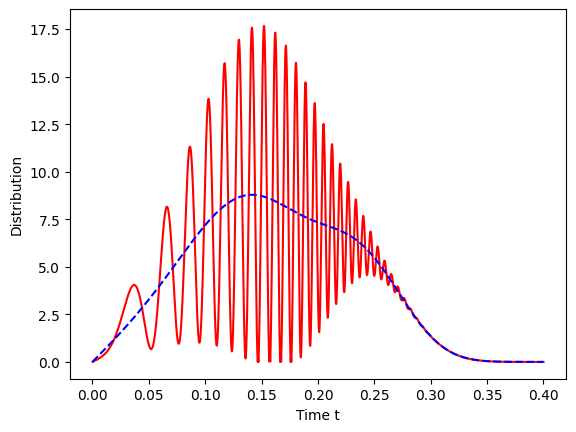

mean_toa =  0.16115698457241737
std_dev_toa =  0.06876560352629695


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1  #fixed
m_1 = 1   #fixed
m_2 = 1   #fixed
k_1 = -10
k_2 = 10
a_1 = 0   #fixed
a_2 = 0   #fixed
sigma_1 = 2
sigma_2 = 2
x = 2
g = 200

# Parameters
v0_1 = hbar*k_1/m_1  # Initial velocity 1
v0_2 = hbar*k_2/m_1  # Initial velocity 1
q_1 = hbar/(2*m_1*sigma_1*np.sqrt(v0_1**2+2*g*x)) # Quantumness 1
q_2 = hbar/(2*m_2*sigma_2*np.sqrt(v0_2**2+2*g*x)) # Quantumness 2
tc_1 = (np.sqrt(v0_1**2+2*g*x)-v0_1)/g  # Classical time 1
tc_2 = (np.sqrt(v0_2**2+2*g*x)-v0_2)/g  # Classical time 2
tc = (tc_1+tc_2)/2  # Average classical time

# Time range
tmin = 0.001 * tc_2
tmax = 2*tc_1
t = np.linspace(tmin, tmax, 10000)

# Tau
tau_1 = (2 * m_1 * sigma_1**2) / hbar
tau_2 = (2 * m_2 * sigma_2**2) / hbar

# Time-dependent variables
sigma_1t = sigma_1 * np.sqrt(1 + ((t**2) / (tau_1**2)))
sigma_2t = sigma_2 * np.sqrt(1 + ((t**2) / (tau_2**2)))

x_1t = a_1 + ((hbar * k_1 / m_1) * t) + ((g * t**2) / 2)
x_2t = a_2 + ((hbar * k_2 / m_2) * t) + ((g * t**2) / 2)

lambda_1t = np.sqrt(hbar * t / m_1)
lambda_2t = np.sqrt(hbar * t / m_2)

k_1t = k_1 + (m_1 * g * t / hbar)
k_2t = k_2 + (m_2 * g * t / hbar)

# u and v terms
u_1 = - (hbar / m_1) * ((x - x_1t) / (2 * sigma_1t**2))
u_2 = - (hbar / m_2) * ((x - x_2t) / (2 * sigma_2t**2))

v_1 = (hbar / m_1) * (((lambda_1t**2) / (4 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)) + ((hbar / m_1) * k_1t)
v_2 = (hbar / m_2) * (((lambda_2t**2) / (4 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)) + ((hbar / m_2) * k_2t)

# rho
rho_1 = (1 / np.sqrt(2 * np.pi * sigma_1t**2)) * np.exp(-((x - x_1t)**2) / (2 * sigma_1t**2))
rho_2 = (1 / np.sqrt(2 * np.pi * sigma_2t**2)) * np.exp(-((x - x_2t)**2) / (2 * sigma_2t**2))

# phases
phi_1 = (lambda_1t**2 / (8 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)**2 + k_1t * x - k_1**2 * lambda_1t**2/2 - (g*k_1*t**2/2)  - ((m_1**2 * g**2 * t**3) / (6 * hbar))
phi_2 = (lambda_2t**2 / (8 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)**2 + k_2t * x - k_2**2 * lambda_2t**2/2 - (g*k_2*t**2/2) - ((m_2**2 * g**2 * t**3) / (6 * hbar))

# current
j = v_1 * rho_1 + v_2 * rho_2 + (u_1 - u_2)*np.sqrt(rho_1 * rho_2)*np.sin(phi_1 - phi_2) + (v_1 + v_2) * np.sqrt(rho_1 * rho_2) * np.cos(phi_1 - phi_2)

# current with no interference
jcl = v_1 * rho_1  +  v_2 * rho_2

pi = abs(j)
picl = abs(jcl)

print('q_1=', q_1, ', q_2=', q_2)
print('tc_1=', tc_1, ', tc_2=', tc_2, ', tc=',tc)

# Plot
#plt.plot(t, j, "k-", linewidth=1.5, label="Current (j)")
plt.plot(t, pi, "r-", linewidth=1.5) #, label="TOA distribution"
plt.plot(t, picl, "b--", linewidth=1.5) # , label="TOA distribution with no interference"
#plt.legend(loc="upper right")
plt.xlabel("Time t")
plt.ylabel("Distribution")
plt.show()

mean_toa = simpson(y=t * pi, x=t) / simpson(y=pi, x=t)
print('mean_toa = ', mean_toa)

mean_square_toa = simpson(y=(t**2) * pi, x=t) / simpson(y=pi, x=t)
std_dev_toa = np.sqrt(mean_square_toa - mean_toa**2)
print('std_dev_toa = ', std_dev_toa)


## Fig 2b: TOA distribution for two Gaussian wavepackets for two different values of x

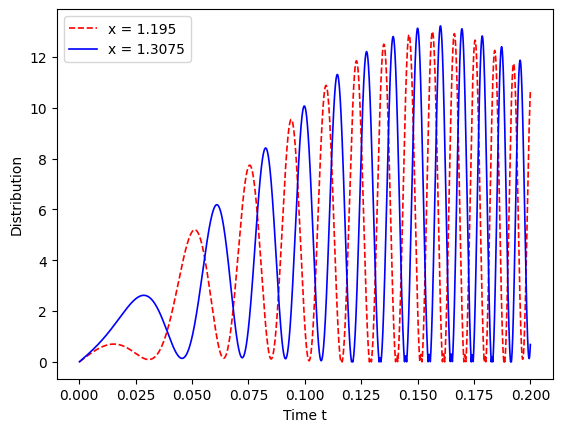

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1  # fixed
m_1 = 1   # fixed
m_2 = 1   # fixed
k_1 = -10
k_2 = 10
a_1 = 0   # fixed
a_2 = 0   # fixed
sigma_1 = 3
sigma_2 = 3
g = 200

# Function to compute |j| for a given x
def compute_pi(x):
    v0_1 = hbar * k_1 / m_1  # Initial velocity 1
    v0_2 = hbar * k_2 / m_1  # Initial velocity 2
    tc_1 = (np.sqrt(v0_1**2 + 2 * g * x) - v0_1) / g  # Classical time 1
    tc_2 = (np.sqrt(v0_2**2 + 2 * g * x) - v0_2) / g  # Classical time 2

    # Time range
    tmin = 0.001 * tc_2
    tmax = 0.2
    t = np.linspace(tmin, tmax, 10000)

    # Tau
    tau_1 = (2 * m_1 * sigma_1**2) / hbar
    tau_2 = (2 * m_2 * sigma_2**2) / hbar

    # Time-dependent variables
    sigma_1t = sigma_1 * np.sqrt(1 + ((t**2) / (tau_1**2)))
    sigma_2t = sigma_2 * np.sqrt(1 + ((t**2) / (tau_2**2)))

    x_1t = a_1 + ((hbar * k_1 / m_1) * t) + ((g * t**2) / 2)
    x_2t = a_2 + ((hbar * k_2 / m_2) * t) + ((g * t**2) / 2)

    lambda_1t = np.sqrt(hbar * t / m_1)
    lambda_2t = np.sqrt(hbar * t / m_2)

    k_1t = k_1 + (m_1 * g * t / hbar)
    k_2t = k_2 + (m_2 * g * t / hbar)

    # u and v terms
    u_1 = - (hbar / m_1) * ((x - x_1t) / (2 * sigma_1t**2))
    u_2 = - (hbar / m_2) * ((x - x_2t) / (2 * sigma_2t**2))

    v_1 = (hbar / m_1) * (((lambda_1t**2) / (4 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)) + ((hbar / m_1) * k_1t)
    v_2 = (hbar / m_2) * (((lambda_2t**2) / (4 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)) + ((hbar / m_2) * k_2t)

    # rho
    rho_1 = (1 / np.sqrt(2 * np.pi * sigma_1t**2)) * np.exp(-((x - x_1t)**2) / (2 * sigma_1t**2))
    rho_2 = (1 / np.sqrt(2 * np.pi * sigma_2t**2)) * np.exp(-((x - x_2t)**2) / (2 * sigma_2t**2))

    # phases
    phi_1 = (lambda_1t**2 / (8 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)**2 + k_1t * x - k_1**2 * lambda_1t**2/2 - (g*k_1*t**2/2)  - ((m_1**2 * g**2 * t**3) / (6 * hbar))
    phi_2 = (lambda_2t**2 / (8 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)**2 + k_2t * x - k_2**2 * lambda_2t**2/2 - (g*k_2*t**2/2) - ((m_2**2 * g**2 * t**3) / (6 * hbar))

    # current
    j = v_1 * rho_1 + v_2 * rho_2 + (u_1 - u_2)*np.sqrt(rho_1 * rho_2)*np.sin(phi_1 - phi_2) + (v_1 + v_2) * np.sqrt(rho_1 * rho_2) * np.cos(phi_1 - phi_2)

    return t, abs(j)

# Compute and plot for x = 1 and x = 1.2
t1, pi1 = compute_pi(1.195)
t2, pi2 = compute_pi(1.3075)

# Mean TOA
tint = np.linspace(0, 1, 10000)
mean_toa1 = simpson(y=t1 * pi1, x=tint) / simpson(y=pi1, x=tint)
mean_toa2 = simpson(y=t2 * pi2, x=tint) / simpson(y=pi2, x=tint)

plt.plot(t1, pi1, "r--", linewidth=1.2, label="x = 1.195")
plt.plot(t2, pi2, "b-", linewidth=1.2, label="x = 1.3075")
plt.legend(loc="upper left")
plt.xlabel("Time t")
plt.ylabel("Distribution")
plt.show()


## Variation of Figure 2b unpublished

mean_toa1 =  0.1685118343146333
mean_toa2 =  0.16778943085907497


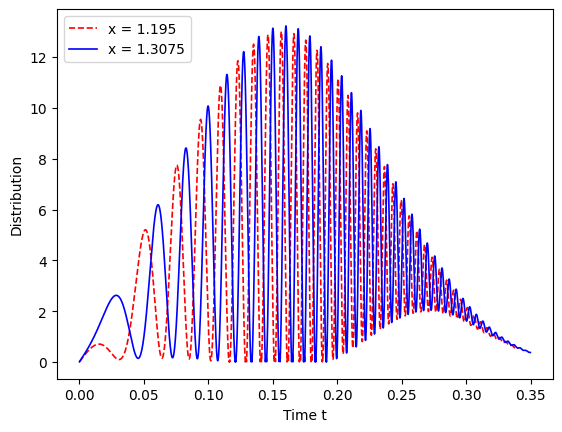

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1  # fixed
m_1 = 1   # fixed
m_2 = 1   # fixed
k_1 = -10
k_2 = 10
a_1 = 0   # fixed
a_2 = 0   # fixed
sigma_1 = 3
sigma_2 = 3
g = 200

# Function to compute |j| for a given x
def compute_pi(x):
    v0_1 = hbar * k_1 / m_1  # Initial velocity 1
    v0_2 = hbar * k_2 / m_1  # Initial velocity 2
    tc_1 = (np.sqrt(v0_1**2 + 2 * g * x) - v0_1) / g  # Classical time 1
    tc_2 = (np.sqrt(v0_2**2 + 2 * g * x) - v0_2) / g  # Classical time 2

    # Time range
    tmin = 0.001 * tc_2
    tmax = 2*tc_1
    t = np.linspace(tmin, tmax, 10000)

    # Tau
    tau_1 = (2 * m_1 * sigma_1**2) / hbar
    tau_2 = (2 * m_2 * sigma_2**2) / hbar

    # Time-dependent variables
    sigma_1t = sigma_1 * np.sqrt(1 + ((t**2) / (tau_1**2)))
    sigma_2t = sigma_2 * np.sqrt(1 + ((t**2) / (tau_2**2)))

    x_1t = a_1 + ((hbar * k_1 / m_1) * t) + ((g * t**2) / 2)
    x_2t = a_2 + ((hbar * k_2 / m_2) * t) + ((g * t**2) / 2)

    lambda_1t = np.sqrt(hbar * t / m_1)
    lambda_2t = np.sqrt(hbar * t / m_2)

    k_1t = k_1 + (m_1 * g * t / hbar)
    k_2t = k_2 + (m_2 * g * t / hbar)

    # u and v terms
    u_1 = - (hbar / m_1) * ((x - x_1t) / (2 * sigma_1t**2))
    u_2 = - (hbar / m_2) * ((x - x_2t) / (2 * sigma_2t**2))

    v_1 = (hbar / m_1) * (((lambda_1t**2) / (4 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)) + ((hbar / m_1) * k_1t)
    v_2 = (hbar / m_2) * (((lambda_2t**2) / (4 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)) + ((hbar / m_2) * k_2t)

    # rho
    rho_1 = (1 / np.sqrt(2 * np.pi * sigma_1t**2)) * np.exp(-((x - x_1t)**2) / (2 * sigma_1t**2))
    rho_2 = (1 / np.sqrt(2 * np.pi * sigma_2t**2)) * np.exp(-((x - x_2t)**2) / (2 * sigma_2t**2))

    # phases
    phi_1 = (lambda_1t**2 / (8 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)**2 + k_1t * x - k_1**2 * lambda_1t**2/2 - (g*k_1*t**2/2)  - ((m_1**2 * g**2 * t**3) / (6 * hbar))
    phi_2 = (lambda_2t**2 / (8 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)**2 + k_2t * x - k_2**2 * lambda_2t**2/2 - (g*k_2*t**2/2) - ((m_2**2 * g**2 * t**3) / (6 * hbar))

    # current
    j = v_1 * rho_1 + v_2 * rho_2 + (u_1 - u_2)*np.sqrt(rho_1 * rho_2)*np.sin(phi_1 - phi_2) + (v_1 + v_2) * np.sqrt(rho_1 * rho_2) * np.cos(phi_1 - phi_2)

    return t, abs(j)

# Compute and plot for x = 1 and x = 1.2
t1, pi1 = compute_pi(1.195)
t2, pi2 = compute_pi(1.3075)

# Mean TOA
tint = np.linspace(0, 1, 10000)
mean_toa1 = simpson(y=t1 * pi1, x=tint) / simpson(y=pi1, x=tint)
mean_toa2 = simpson(y=t2 * pi2, x=tint) / simpson(y=pi2, x=tint)

print('mean_toa1 = ', mean_toa1)
print('mean_toa2 = ', mean_toa2)

plt.plot(t1, pi1, "r--", linewidth=1.2, label="x = 1.195")
plt.plot(t2, pi2, "b-", linewidth=1.2, label="x = 1.3075")
plt.legend(loc="upper left")
plt.xlabel("Time t")
plt.ylabel("Distribution")
plt.show()


# Figure 3: Mean and Stardard Dev TOA

## Fig 3a: Mean TOA

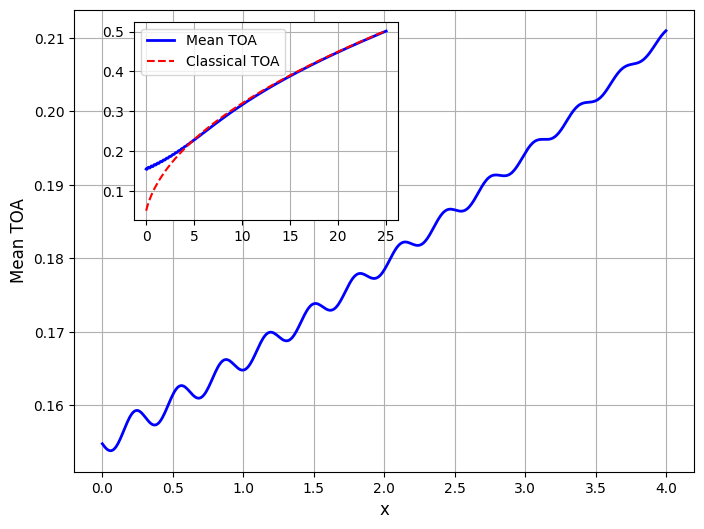

In [ ]:

# Create the figure
fig, ax = plt.subplots(figsize=(8, 6))

# Main plot (first code: smaller x-range, but we want it larger in the final figure)
ax.plot(x_values_main, mean_toa_main, color="b", linewidth=2, label="Mean TOA (tmax=1)")
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("Mean TOA", fontsize=12)
ax.grid()
#ax.legend()

# Subfigure (second code: larger x-range)
ax_inset = fig.add_axes([0.20, 0.53, 0.33, 0.33])  # [left, bottom, width, height] in figure coords
ax_inset.plot(x_values_inset, mean_toa_inset, color="b", linewidth=2, label="Mean TOA")
ax_inset.plot(x_values_inset, tc_average_inset, color="r", linestyle="--", label=r"Classical TOA")
#ax_inset.set_title("Inset: Larger x-range", fontsize=9)
ax_inset.grid(True)

# Optionally remove or reduce ticks in the inset:
# ax_inset.set_xticks([])
# ax_inset.set_yticks([])
# or keep them if you prefer:
#ax_inset.set_xlabel("x", fontsize=10)
#ax_inset.set_ylabel("Mean TOA", fontsize=10)
ax_inset.legend(fontsize=10)

plt.show()

## Fig 3b: Standard deviation

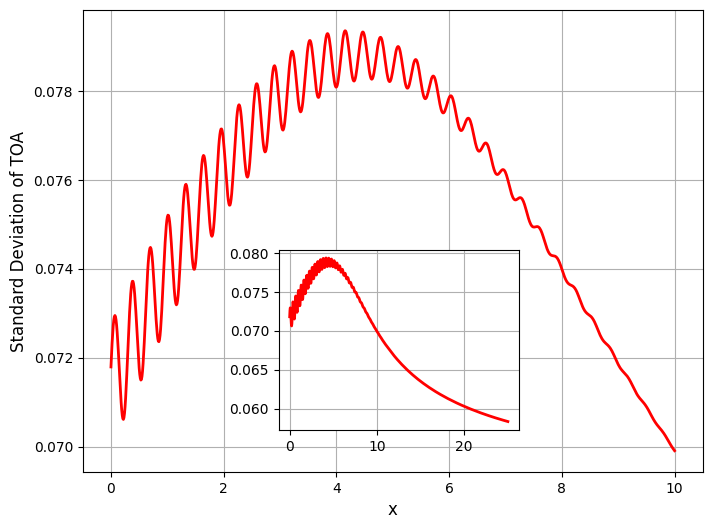

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1  # fixed
m_1 = 1   # fixed
m_2 = 1   # fixed
k_1 = -10
k_2 = 10
a_1 = 0   # fixed
a_2 = 0   # fixed
sigma_1 = 3
sigma_2 = 3
g = 200

def compute_std_dev_toa(x, tmax=1.0, n_t=10000):
    """
    Computes the standard deviation of the Time of Arrival (TOA) distribution
    for a given position x, integrating from t=0 to t=tmax using n_t time steps.
    """
    # Create time array
    t = np.linspace(0, tmax, n_t)

    # Tau
    tau_1 = (2 * m_1 * sigma_1**2) / hbar
    tau_2 = (2 * m_2 * sigma_2**2) / hbar

    # Time-dependent widths
    sigma_1t = sigma_1 * np.sqrt(1 + (t**2 / tau_1**2))
    sigma_2t = sigma_2 * np.sqrt(1 + (t**2 / tau_2**2))

    # Time-dependent centers
    x_1t = a_1 + (hbar * k_1 / m_1)*t + 0.5*g*(t**2)
    x_2t = a_2 + (hbar * k_2 / m_2)*t + 0.5*g*(t**2)

    # Time-dependent wave numbers
    lambda_1t = np.sqrt(hbar * t / m_1)
    lambda_2t = np.sqrt(hbar * t / m_2)
    k_1t = k_1 + (m_1 * g * t / hbar)
    k_2t = k_2 + (m_2 * g * t / hbar)

    # u and v terms
    u_1 = - (hbar / m_1)*((x - x_1t)/(2*sigma_1t**2))
    u_2 = - (hbar / m_2)*((x - x_2t)/(2*sigma_2t**2))

    v_1 = (hbar / m_1)*((lambda_1t**2)/(4*sigma_1**2*sigma_1t**2)*(x - x_1t)) + (hbar*k_1t / m_1)
    v_2 = (hbar / m_2)*((lambda_2t**2)/(4*sigma_2**2*sigma_2t**2)*(x - x_2t)) + (hbar*k_2t / m_2)

    # Densities
    rho_1 = (1 / np.sqrt(2*np.pi*sigma_1t**2)) * np.exp(-((x - x_1t)**2)/(2*sigma_1t**2))
    rho_2 = (1 / np.sqrt(2*np.pi*sigma_2t**2)) * np.exp(-((x - x_2t)**2)/(2*sigma_2t**2))

    # Phases
    phi_1 = ( (lambda_1t**2)/(8*sigma_1**2*sigma_1t**2) )*(x - x_1t)**2 \
             + k_1t*x - 0.5*(k_1**2)*(lambda_1t**2) \
             - 0.5*g*k_1*(t**2) - (m_1**2*g**2/(6*hbar))*(t**3)

    phi_2 = ( (lambda_2t**2)/(8*sigma_2**2*sigma_2t**2) )*(x - x_2t)**2 \
             + k_2t*x - 0.5*(k_2**2)*(lambda_2t**2) \
             - 0.5*g*k_2*(t**2) - (m_2**2*g**2/(6*hbar))*(t**3)

    # Probability current
    j = (v_1*rho_1 + v_2*rho_2
         + (u_1 - u_2)*np.sqrt(rho_1*rho_2)*np.sin(phi_1 - phi_2)
         + (v_1 + v_2)*np.sqrt(rho_1*rho_2)*np.cos(phi_1 - phi_2))

    pi = np.abs(j)  # Probability flux

    # Compute standard deviation of TOA
    mean_toa = simpson(y=t*pi, x=t) / simpson(y=pi, x=t)
    mean_sq_toa = simpson(y=(t**2)*pi, x=t) / simpson(y=pi, x=t)
    std_dev_toa = np.sqrt(mean_sq_toa - mean_toa**2)

    return std_dev_toa


# --------------------------------------------------------------------
# 1) Main figure (SMALLER x-range, bigger on the final plot)
#    x from 0 to 4, keep tmax=1
# --------------------------------------------------------------------
x_values_main = np.linspace(0, 10, 1000)
std_dev_main = [compute_std_dev_toa(x, tmax=1.0, n_t=8000) for x in x_values_main]

# --------------------------------------------------------------------
# 2) Inset figure (LARGER x-range, smaller subfigure)
#    x from 0 to 25, also tmax=1, but reduce resolution to save time
# --------------------------------------------------------------------
x_values_inset = np.linspace(0, 25, 800)
std_dev_inset = [compute_std_dev_toa(x, tmax=1.0, n_t=4000) for x in x_values_inset]

# --------------------------------------------------------------------
# Create a single figure with:
#   - Main axes for the smaller x-range
#   - Inset axes for the larger x-range
# --------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Main plot (smaller x-range, standard deviation of TOA)
ax.plot(x_values_main, std_dev_main, color='r', linewidth=2,       label="Std. Dev. TOA (x in [0,4])")
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("Standard Deviation of TOA", fontsize=12)
#ax.legend()
ax.grid(True)

# Create inset axes for the larger x-range
# [left, bottom, width, height] in figure coordinates
ax_inset = fig.add_axes([0.37, 0.18, 0.3, 0.3])
ax_inset.plot(x_values_inset, std_dev_inset, color='r', linewidth=2)
#ax_inset.set_title("Inset: x in [0,25]", fontsize=9)
ax_inset.grid(True)

# Optionally remove ticks in the inset or leave them
#ax_inset.set_xlabel("x (inset)", fontsize=8)
#ax_inset.set_ylabel("Std. Dev. TOA", fontsize=8)

plt.show()


# Figure 4: Mean TOA for a free-falling hydrogen atom in the superposition of two Gaussian wavepackets

## Figure 4b: TOA distribution for two different values of x

mean_toa1 =  0.009515816682068764
mean_toa2 =  0.006867035363373886


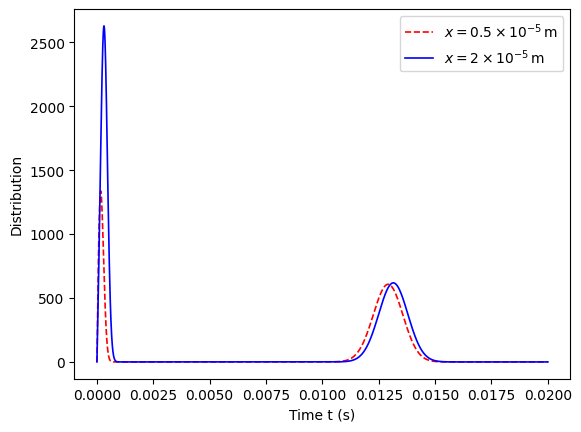

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1.05e-34  # fixed
m_1 = 1.67e-27   # fixed
m_2 = 1.67e-27   # fixed
sigma_1 = 1e-5
sigma_2 = 1e-5
g = 9.8
k_1 = -1e6
k_2 = 1e6
a_1 = 0   # fixed
a_2 = 0   # fixed

# Function to compute |j| for a given x
def compute_pi(x):
    v0_1 = hbar * k_1 / m_1  # Initial velocity 1
    v0_2 = hbar * k_2 / m_1  # Initial velocity 2
    tc_1 = (np.sqrt(v0_1**2 + 2 * g * x) - v0_1) / g  # Classical time 1
    tc_2 = (np.sqrt(v0_2**2 + 2 * g * x) - v0_2) / g  # Classical time 2

    # Time range
    tmin = 0
    tmax = 0.02
    t = np.linspace(tmin, tmax, 10000)

    # Tau
    tau_1 = (2 * m_1 * sigma_1**2) / hbar
    tau_2 = (2 * m_2 * sigma_2**2) / hbar

    # Time-dependent variables
    sigma_1t = sigma_1 * np.sqrt(1 + ((t**2) / (tau_1**2)))
    sigma_2t = sigma_2 * np.sqrt(1 + ((t**2) / (tau_2**2)))

    x_1t = a_1 + ((hbar * k_1 / m_1) * t) + ((g * t**2) / 2)
    x_2t = a_2 + ((hbar * k_2 / m_2) * t) + ((g * t**2) / 2)

    lambda_1t = np.sqrt(hbar * t / m_1)
    lambda_2t = np.sqrt(hbar * t / m_2)

    k_1t = k_1 + (m_1 * g * t / hbar)
    k_2t = k_2 + (m_2 * g * t / hbar)

    # u and v terms
    u_1 = - (hbar / m_1) * ((x - x_1t) / (2 * sigma_1t**2))
    u_2 = - (hbar / m_2) * ((x - x_2t) / (2 * sigma_2t**2))

    v_1 = (hbar / m_1) * (((lambda_1t**2) / (4 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)) + ((hbar / m_1) * k_1t)
    v_2 = (hbar / m_2) * (((lambda_2t**2) / (4 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)) + ((hbar / m_2) * k_2t)

    # rho
    rho_1 = (1 / np.sqrt(2 * np.pi * sigma_1t**2)) * np.exp(-((x - x_1t)**2) / (2 * sigma_1t**2))
    rho_2 = (1 / np.sqrt(2 * np.pi * sigma_2t**2)) * np.exp(-((x - x_2t)**2) / (2 * sigma_2t**2))

    # phases
    phi_1 = (lambda_1t**2 / (8 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)**2 + k_1t * x - k_1**2 * lambda_1t**2/2 - (g*k_1*t**2/2)  - ((m_1**2 * g**2 * t**3) / (6 * hbar))
    phi_2 = (lambda_2t**2 / (8 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)**2 + k_2t * x - k_2**2 * lambda_2t**2/2 - (g*k_2*t**2/2) - ((m_2**2 * g**2 * t**3) / (6 * hbar))

    # current
    j = v_1 * rho_1 + v_2 * rho_2 + (u_1 - u_2)*np.sqrt(rho_1 * rho_2)*np.sin(phi_1 - phi_2) + (v_1 + v_2) * np.sqrt(rho_1 * rho_2) * np.cos(phi_1 - phi_2)

    return t, abs(j)

# Compute and plot for x = 1 and x = 1.2
t1, pi1 = compute_pi(0.5e-5)
t2, pi2 = compute_pi(2e-5)

# Mean TOA
tint = np.linspace(0, 1, 10000)
mean_toa1 = simpson(y=t1 * pi1, x=tint) / simpson(y=pi1, x=tint)
mean_toa2 = simpson(y=t2 * pi2, x=tint) / simpson(y=pi2, x=tint)

print('mean_toa1 = ', mean_toa1)
print('mean_toa2 = ', mean_toa2)

plt.plot(t1, pi1, "r--", linewidth=1.2, label=r"$x = 0.5 \times 10^{-5} \, \mathrm{m}$")
plt.plot(t2, pi2, "b-", linewidth=1.2, label=r"$x = 2 \times 10^{-5} \, \mathrm{m}$")
plt.legend(loc="upper right")
plt.xlabel("Time t (s)")
plt.ylabel("Distribution")
plt.show()


## Figure 4a: Mean TOA vs. x

-0.06287425149700598
0.06287425149700598


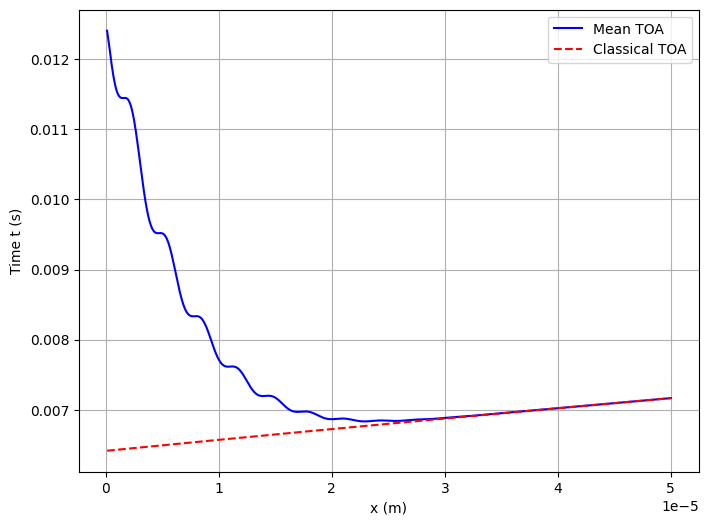

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Constants
hbar = 1.05e-34  # fixed
m_1 = 1.67e-27   # fixed
m_2 = 1.67e-27   # fixed
sigma_1 = 1e-5
sigma_2 = 1e-5
g = 9.8
k_1 = -1e6
k_2 = 1e6
a_1 = 0   # fixed
a_2 = 0   # fixed

v0_1 = hbar * k_1 / m_1  # Initial velocity 1
v0_2 = hbar * k_2 / m_2  # Initial velocity 2

print(v0_1)
print(v0_2)

# Function to compute mean TOA for a given x
def compute_mean_toa(x):


    # Time range
    tmin = 0
    tmax = 1
    t = np.linspace(tmin, tmax, 20000)

     # Tau
    tau_1 = (2 * m_1 * sigma_1**2) / hbar
    tau_2 = (2 * m_2 * sigma_2**2) / hbar

    # Time-dependent variables
    sigma_1t = sigma_1 * np.sqrt(1 + ((t**2) / (tau_1**2)))
    sigma_2t = sigma_2 * np.sqrt(1 + ((t**2) / (tau_2**2)))

    x_1t = a_1 + ((hbar * k_1 / m_1) * t) + ((g * t**2) / 2)
    x_2t = a_2 + ((hbar * k_2 / m_2) * t) + ((g * t**2) / 2)

    lambda_1t = np.sqrt(hbar * t / m_1)
    lambda_2t = np.sqrt(hbar * t / m_2)

    k_1t = k_1 + (m_1 * g * t / hbar)
    k_2t = k_2 + (m_2 * g * t / hbar)

    # u and v terms
    u_1 = - (hbar / m_1) * ((x - x_1t) / (2 * sigma_1t**2))
    u_2 = - (hbar / m_2) * ((x - x_2t) / (2 * sigma_2t**2))

    v_1 = (hbar / m_1) * (((lambda_1t**2) / (4 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)) + ((hbar / m_1) * k_1t)
    v_2 = (hbar / m_2) * (((lambda_2t**2) / (4 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)) + ((hbar / m_2) * k_2t)

    # rho
    rho_1 = (1 / np.sqrt(2 * np.pi * sigma_1t**2)) * np.exp(-((x - x_1t)**2) / (2 * sigma_1t**2))
    rho_2 = (1 / np.sqrt(2 * np.pi * sigma_2t**2)) * np.exp(-((x - x_2t)**2) / (2 * sigma_2t**2))

    # phases
    phi_1 = (lambda_1t**2 / (8 * sigma_1**2 * sigma_1t**2)) * (x - x_1t)**2 + k_1t * x - k_1**2 * lambda_1t**2/2 - (g*k_1*t**2/2)  - ((m_1**2 * g**2 * t**3) / (6 * hbar))
    phi_2 = (lambda_2t**2 / (8 * sigma_2**2 * sigma_2t**2)) * (x - x_2t)**2 + k_2t * x - k_2**2 * lambda_2t**2/2 - (g*k_2*t**2/2) - ((m_2**2 * g**2 * t**3) / (6 * hbar))

    # current
    j = v_1 * rho_1 + v_2 * rho_2 + (u_1 - u_2)*np.sqrt(rho_1 * rho_2)*np.sin(phi_1 - phi_2) + (v_1 + v_2) * np.sqrt(rho_1 * rho_2) * np.cos(phi_1 - phi_2)

    pi = abs(j)

    mean_toa = simpson(y=t * pi, x=t) / simpson(y=pi, x=t)
    return mean_toa

# Define x values
x_values = np.linspace(1e-7, 5e-5, 1000)

# Compute mean TOA values
mean_toa_values = [compute_mean_toa(x) for x in x_values]

# Compute tc_1 and tc_2
tc_1_values = (np.sqrt((hbar * k_1 / m_1)**2 + 2 * g * x_values) - (hbar * k_1 / m_1)) / g
tc_2_values = (np.sqrt((hbar * k_2 / m_2)**2 + 2 * g * x_values) - (hbar * k_2 / m_2)) / g

# Compute tc_average
tc_average_values = (tc_1_values + tc_2_values) / 2



# Comparison
Ratio = mean_toa_values/tc_average_values

# Compute q
q_1 = hbar / (2 * m_1 * sigma_1 * np.sqrt((hbar * k_1 / m_1)**2 + 2 * g * x_values))



# Create a combined plot
plt.figure(figsize=(8, 6))

# Plot Mean TOA
plt.plot(x_values, mean_toa_values, linewidth=1.5, label="Mean TOA", color="b")

# Plot tc_average
plt.plot(x_values, tc_average_values, linewidth=1.5, label=r"Classical TOA", color="r", linestyle="dashed")

# Labels and legend
plt.xlabel("x (m)")
plt.ylabel("Time t (s)")
plt.legend()
plt.grid()

# Show the combined plot
plt.show()



